In [9]:
import os
import torch
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import classification_report, f1_score, accuracy_score
from torch.utils.data import Dataset, DataLoader
from transformers import AutoTokenizer, AutoModelForSequenceClassification
from torch.optim import AdamW

MODEL_NAME = "bert-base-uncased"
MAX_LEN = 128
BATCH_SIZE = 16
EPOCHS = 3
LR = 2e-5
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
OUTPUT_DIR = "./saved_model"

print(f"Using device: {DEVICE}")

Using device: cpu


In [10]:
train_df = pd.read_csv(r"D:\DS\MiniProjects\Comment Toxicity\Dataset\train.csv")
test_df = pd.read_csv(r"D:\DS\MiniProjects\Comment Toxicity\Dataset\test.csv")


In [5]:
train_df.head()

,id,comment_text,toxic,severe_toxic,obscene,threat,insult,identity_hate
0,0000997932d777bf,Explanation\nWhy the edits made under my usern...,0,0,0,0,0,0
1,000103f0d9cfb60f,D'aww! He matches this background colour I'm s...,0,0,0,0,0,0
2,000113f07ec002fd,"Hey man, I'm really not trying to edit war. It...",0,0,0,0,0,0
3,0001b41b1c6bb37e,"""\nMore\nI can't make any real suggestions on ...",0,0,0,0,0,0
4,0001d958c54c6e35,"You, sir, are my hero. Any chance you remember...",0,0,0,0,0,0


In [6]:
train_df.tail()

,id,comment_text,toxic,severe_toxic,obscene,threat,insult,identity_hate
159566,ffe987279560d7ff,""":::::And for the second time of asking, when ...",0,0,0,0,0,0
159567,ffea4adeee384e90,You should be ashamed of yourself \n\nThat is ...,0,0,0,0,0,0
159568,ffee36eab5c267c9,"Spitzer \n\nUmm, theres no actual article for ...",0,0,0,0,0,0
159569,fff125370e4aaaf3,And it looks like it was actually you who put ...,0,0,0,0,0,0
159570,fff46fc426af1f9a,"""\nAnd ... I really don't think you understand...",0,0,0,0,0,0


In [12]:
100*train_df.isnull().sum()/train_df.shape[0]

id               0.0
comment_text     0.0
toxic            0.0
severe_toxic     0.0
obscene          0.0
threat           0.0
insult           0.0
identity_hate    0.0
dtype: float64

In [13]:
100*test_df.isnull().sum()/test_df.shape[0]

id              0.0
comment_text    0.0
dtype: float64

In [14]:
test_df.info()

<class 'pandas.DataFrame'>
RangeIndex: 153164 entries, 0 to 153163
Data columns (total 2 columns):
 #   Column        Non-Null Count   Dtype
---  ------        --------------   -----
 0   id            153164 non-null  str  
 1   comment_text  153164 non-null  str  
dtypes: str(2)
memory usage: 2.3 MB


In [15]:
train_df.info()

<class 'pandas.DataFrame'>
RangeIndex: 159571 entries, 0 to 159570
Data columns (total 8 columns):
 #   Column         Non-Null Count   Dtype
---  ------         --------------   -----
 0   id             159571 non-null  str  
 1   comment_text   159571 non-null  str  
 2   toxic          159571 non-null  int64
 3   severe_toxic   159571 non-null  int64
 4   obscene        159571 non-null  int64
 5   threat         159571 non-null  int64
 6   insult         159571 non-null  int64
 7   identity_hate  159571 non-null  int64
dtypes: int64(6), str(2)
memory usage: 9.7 MB


In [18]:
label_cols = ['toxic', 'severe_toxic', 'obscene', 'threat', 'insult', 'identity_hate']
train_df['is_toxic'] = train_df[label_cols].max(axis=1)

In [19]:
print(train_df['is_toxic'].value_counts())

is_toxic
0    143346
1     16225
Name: count, dtype: int64


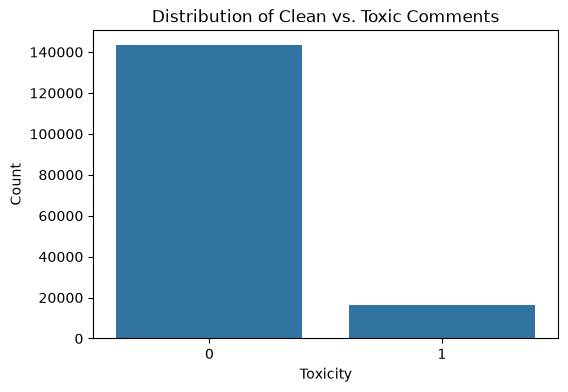

In [23]:
plt.figure(figsize=(6, 4))
sns.countplot(x='is_toxic', data=train_df)
plt.title("Distribution of Clean vs. Toxic Comments")
plt.xlabel("Toxicity")
plt.ylabel("Count")
plt.show()

In [30]:
from sklearn.model_selection import train_test_split
train_df, val_df = train_test_split(train_df, test_size=0.2, random_state=42, stratify=train_df['is_toxic'])

**PRE-PROCESSING**

In [24]:
import re
import nltk
from nltk.corpus import stopwords

In [27]:
nltk.download('stopwords')
stop_words = set(stopwords.words('english'))

def clean_and_preprocess(text):
    text = str(text).lower()
    text = re.sub(r'[^a-zA-Z0-9\s]', '', text)
    
    words = text.split()
    filtered_words = [word for word in words if word not in stop_words]
    
    return "️ ".join(filtered_words)

train_df['cleaned_comment'] = train_df['comment_text'].apply(clean_and_preprocess)

[nltk_data] Downloading package stopwords to
[nltk_data]     C:\Users\Admin\AppData\Roaming\nltk_data...
[nltk_data]   Package stopwords is already up-to-date!


In [31]:
tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)

train_encodings = tokenizer(
    list(train_df['comment_text']),
    truncation=True,
    padding=True,
    max_length=MAX_LEN,
    return_tensors="pt"
)

val_encodings = tokenizer(
    list(val_df['comment_text']),
    truncation=True,
    padding=True,
    max_length=MAX_LEN,
    return_tensors="pt"
)

train_labels = torch.tensor(train_df['is_toxic'].values, dtype=torch.long)
val_labels = torch.tensor(val_df['is_toxic'].values, dtype=torch.long)


from torch.utils.data import TensorDataset

train_dataset = TensorDataset(
    train_encodings['input_ids'],
    train_encodings['attention_mask'],
    train_labels
)

val_dataset = TensorDataset(
    val_encodings['input_ids'],
    val_encodings['attention_mask'],
    val_labels
)

train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True)
val_loader = DataLoader(val_dataset, batch_size=BATCH_SIZE, shuffle=False)